In [39]:
## task 1
import numpy as np

In [11]:
import pandas as pd
df=pd.read_csv("Dataset .csv")
df.head(16)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229
5,18189371,Din Tai Fung,162,Mandaluyong City,"Ground Floor, Mega Fashion Hall, SM Megamall, ...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056314,14.583764,Chinese,...,Botswana Pula(P),No,No,No,No,3,4.4,Green,Very Good,336
6,6300781,Buffet 101,162,Pasay City,"Building K, SM By The Bay, Sunset Boulevard, M...","SM by the Bay, Mall of Asia Complex, Pasay City","SM by the Bay, Mall of Asia Complex, Pasay Cit...",120.979667,14.531333,"Asian, European",...,Botswana Pula(P),Yes,No,No,No,4,4.0,Green,Very Good,520
7,6301290,Vikings,162,Pasay City,"Building B, By The Bay, Seaside Boulevard, Mal...","SM by the Bay, Mall of Asia Complex, Pasay City","SM by the Bay, Mall of Asia Complex, Pasay Cit...",120.979333,14.540000,"Seafood, Filipino, Asian, European",...,Botswana Pula(P),Yes,No,No,No,4,4.2,Green,Very Good,677
8,6300010,Spiral - Sofitel Philippine Plaza Manila,162,Pasay City,"Plaza Level, Sofitel Philippine Plaza Manila, ...","Sofitel Philippine Plaza Manila, Pasay City","Sofitel Philippine Plaza Manila, Pasay City, P...",120.980090,14.552990,"European, Asian, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.9,Dark Green,Excellent,621
9,6314987,Locavore,162,Pasig City,"Brixton Technology Center, 10 Brixton Street, ...",Kapitolyo,"Kapitolyo, Pasig City",121.056532,14.572041,Filipino,...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,532


(array([8676.,   64.,    0.,    0.,   21.,    0.,   40.,   42.,  100.,
         608.]),
 array([  1. ,  22.5,  44. ,  65.5,  87. , 108.5, 130. , 151.5, 173. ,
        194.5, 216. ]),
 <BarContainer object of 10 artists>)

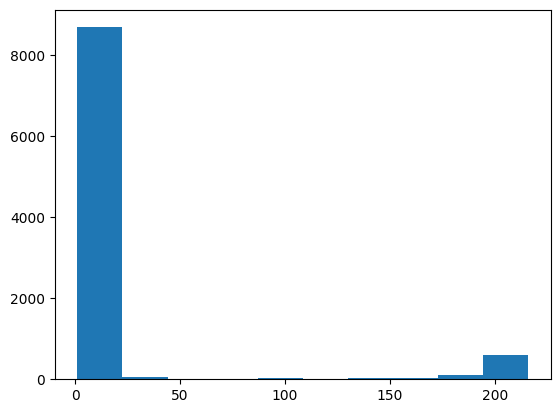

In [3]:
import matplotlib.pyplot as plt
plt.hist(df["Country Code"])

In [4]:
#Checking whether there are null values or not 
def nullcheck():
    a=df.isnull().sum()
    l=df.count()
    print(a)
    df["Cuisines"]=df["Cuisines"].fillna("unknown")
    print("Null values filed by { Unknown }")

nullcheck()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64
Null values filed by { Unknown }


In [18]:
restaurants = df.copy()

# Standardize column names
restaurants.columns = (
    restaurants.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Fill the 9 missing cuisine entries
restaurants["cuisines"] = (
    restaurants["cuisines"]
    .fillna("Unknown")
    .astype(str)
)

# Remove duplicate restaurant IDs, if any
restaurants = restaurants.drop_duplicates(
    subset="restaurant_id"
)

# Clean text columns
text_columns = [
    "restaurant_name",
    "city",
    "locality",
    "cuisines",
    "currency"
]

for col in text_columns:
    restaurants[col] = restaurants[col].str.strip()

print("Cleaned dataset shape:", restaurants.shape)
print("Missing cuisines:", restaurants["cuisines"].isna().sum())
print("Duplicate restaurant IDs:",
      restaurants["restaurant_id"].duplicated().sum())

Cleaned dataset shape: (9551, 21)
Missing cuisines: 0
Duplicate restaurant IDs: 0


In [19]:
print(restaurants.columns.tolist())

display(
    restaurants[
        ["restaurant_name", "city", "cuisines",
         "price_range", "aggregate_rating", "votes"]
    ].head(10)
)


['restaurant_id', 'restaurant_name', 'country_code', 'city', 'address', 'locality', 'locality_verbose', 'longitude', 'latitude', 'cuisines', 'average_cost_for_two', 'currency', 'has_table_booking', 'has_online_delivery', 'is_delivering_now', 'switch_to_order_menu', 'price_range', 'aggregate_rating', 'rating_color', 'rating_text', 'votes']


,restaurant_name,city,cuisines,price_range,aggregate_rating,votes
0,Le Petit Souffle,Makati City,"French, Japanese, Desserts",3,4.8,314
1,Izakaya Kikufuji,Makati City,Japanese,3,4.5,591
2,Heat - Edsa Shangri-La,Mandaluyong City,"Seafood, Asian, Filipino, Indian",4,4.4,270
3,Ooma,Mandaluyong City,"Japanese, Sushi",4,4.9,365
4,Sambo Kojin,Mandaluyong City,"Japanese, Korean",4,4.8,229
5,Din Tai Fung,Mandaluyong City,Chinese,3,4.4,336
6,Buffet 101,Pasay City,"Asian, European",4,4.0,520
7,Vikings,Pasay City,"Seafood, Filipino, Asian, European",4,4.2,677
8,Spiral - Sofitel Philippine Plaza Manila,Pasay City,"European, Asian, Indian",4,4.9,621
9,Locavore,Pasig City,Filipino,3,4.8,532


In [20]:
restaurants["cuisines"] = (
    restaurants["cuisines"]
    .fillna("Unknown")
    .astype(str)
    .str.lower()
    .str.strip()
)

display(restaurants[["restaurant_name", "cuisines"]].head(10))

,restaurant_name,cuisines
0,Le Petit Souffle,"french, japanese, desserts"
1,Izakaya Kikufuji,japanese
2,Heat - Edsa Shangri-La,"seafood, asian, filipino, indian"
3,Ooma,"japanese, sushi"
4,Sambo Kojin,"japanese, korean"
5,Din Tai Fung,chinese
6,Buffet 101,"asian, european"
7,Vikings,"seafood, filipino, asian, european"
8,Spiral - Sofitel Philippine Plaza Manila,"european, asian, indian"
9,Locavore,filipino


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    tokenizer=lambda text: [
        cuisine.strip() for cuisine in text.split(",")
    ],
    token_pattern=None,
    lowercase=False
)

cuisine_matrix = tfidf.fit_transform(restaurants["cuisines"])

print("Cuisine matrix shape:", cuisine_matrix.shape)
print("Number of cuisine features:", len(tfidf.get_feature_names_out()))

Cuisine matrix shape: (9551, 146)
Number of cuisine features: 146


In [22]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(cuisine_matrix)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (9551, 9551)


In [23]:
def recommend_similar_restaurants(restaurant_name, top_n=10):
    matches = restaurants.index[
        restaurants["restaurant_name"].str.lower()
        == restaurant_name.lower()
    ].tolist()

    if not matches:
        return "Restaurant not found. Check the name."

    restaurant_idx = matches[0]

    scores = list(enumerate(similarity_matrix[restaurant_idx]))

    # Exclude the restaurant itself
    scores = [
        (idx, score)
        for idx, score in scores
        if idx != restaurant_idx
    ]

    scores.sort(key=lambda item: item[1], reverse=True)

    recommended_indices = [idx for idx, score in scores[:top_n]]

    result = restaurants.loc[
        recommended_indices,
        [
            "restaurant_name",
            "city",
            "cuisines",
            "price_range",
            "aggregate_rating"
        ]
    ].copy()

    result["similarity_score"] = [
        round(score, 3)
        for idx, score in scores[:top_n]
    ]

    return result.reset_index(drop=True)

In [29]:
recommend_similar_restaurants("Ooma", top_n=1)

,restaurant_name,city,cuisines,price_range,aggregate_rating,similarity_score
0,Kawa Sushi,S��o Paulo,"sushi, japanese",4,3.5,1.0


In [35]:
from sklearn.preprocessing import MultiLabelBinarizer

# Convert cuisines into lists
cuisine_lists = restaurants["cuisines"].apply(
    lambda x: [c.strip() for c in x.lower().split(",")]
)

# Initialize MultiLabelBinarizer
mlb = MultiLabelBinarizer()

# Convert cuisines into numerical vectors
cuisine_binary = mlb.fit_transform(cuisine_lists)

print("Cuisine matrix shape:", cuisine_binary.shape)
print("Total unique cuisines:", len(mlb.classes_))

Cuisine matrix shape: (9551, 146)
Total unique cuisines: 146


In [36]:
def recommend_restaurants(
    city,
    preferred_cuisines,
    price_range=None,
    min_rating=0,
    top_n=10
):
    # Normalize user inputs
    city = city.strip().lower()

    preferred_cuisines = [
        cuisine.strip().lower()
        for cuisine in preferred_cuisines
    ]

    # Find restaurants in the selected city
    candidates = restaurants[
        restaurants["city"].str.lower() == city
    ].copy()

    # Apply price filter if supplied
    if price_range is not None:
        candidates = candidates[
            candidates["price_range"] == price_range
        ]

    # Exclude unrated restaurants and apply minimum rating
    candidates = candidates[
        candidates["aggregate_rating"] >= min_rating
    ]

    if candidates.empty:
        return "No restaurants match these preferences."

    # Find cuisine feature indices
    available_cuisines = {
        cuisine.lower(): i
        for i, cuisine in enumerate(mlb.classes_)
    }

    unknown = [
        cuisine for cuisine in preferred_cuisines
        if cuisine not in available_cuisines
    ]

    if unknown:
        print("Cuisine not found in dataset:", unknown)

    selected_features = [
        available_cuisines[cuisine]
        for cuisine in preferred_cuisines
        if cuisine in available_cuisines
    ]

    if not selected_features:
        return "No valid preferred cuisines found."

    # Create a user preference vector
    user_vector = np.zeros(len(mlb.classes_))
    user_vector[selected_features] = 1

    # Calculate similarity between user preferences and restaurants
    candidate_vectors = cuisine_binary[candidates.index]
    scores = cosine_similarity(
        candidate_vectors, user_vector.reshape(1, -1)
    ).flatten()

    candidates["similarity_score"] = scores

    # Rank by cuisine similarity, then rating
    candidates = candidates.sort_values(
        ["similarity_score", "aggregate_rating", "votes"],
        ascending=[False, False, False]
    )

    columns = [
        "restaurant_name",
        "city",
        "cuisines",
        "price_range",
        "aggregate_rating",
        "votes",
        "similarity_score"
    ]

    result = candidates[columns].head(top_n).copy()
    result["similarity_score"] = result["similarity_score"].round(3)

    return result.reset_index(drop=True)

In [37]:
restaurants["city"].value_counts().head(10)

city
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Amritsar          21
Ahmedabad         21
Lucknow           21
Guwahati          21
Name: count, dtype: int64

In [40]:
recommend_restaurants(
    city="New Delhi",
    preferred_cuisines=["Italian", "Pizza"],
    price_range=2,
    min_rating=4.0,
    top_n=10
)

,restaurant_name,city,cuisines,price_range,aggregate_rating,votes,similarity_score
0,Tossin Pizza,New Delhi,"pizza, italian",2,4.1,647,1.000
1,Sinyora's,New Delhi,italian,2,4.0,51,0.707
2,Napoli Pizza,New Delhi,pizza,2,4.0,41,0.707
3,The Society Cafe,New Delhi,"cafe, italian",2,4.1,149,0.500
4,Big Yellow Door,New Delhi,"cafe, italian, fast food",2,4.3,3986,0.408
5,Big Yellow Door,New Delhi,"cafe, fast food, italian",2,4.3,214,0.408
6,Big Yellow Door,New Delhi,"cafe, fast food, italian",2,4.2,3311,0.408
7,YOLO 21,New Delhi,"cafe, italian, continental",2,4.2,1526,0.408
8,Superstar Caf��,New Delhi,"cafe, continental, italian",2,4.2,530,0.408
9,Healthy Routes,New Delhi,"healthy food, continental, italian",2,4.0,361,0.408


In [76]:
results = recommend_restaurants(
    city="Makati City",
    preferred_cuisines=["Japanese" ],
    price_range=3,
    min_rating=4.5,
    top_n=10
)

display(results)

,restaurant_name,city,cuisines,price_range,aggregate_rating,votes,similarity_score
0,Izakaya Kikufuji,Makati City,japanese,3,4.5,591,1.000
1,Le Petit Souffle,Makati City,"french, japanese, desserts",3,4.8,314,0.577


In [68]:
def recommend_restaurants_v2(
    city,
    preferred_cuisines,
    price_range=None,
    min_rating=0,
    top_n=10,
    online_delivery=None,
    table_booking=None
):

    # 1. Filter by city
    candidates = restaurants[
        restaurants["city"].str.lower() == city.strip().lower()
    ].copy()

    # 2. Filter by price range
    if price_range is not None:
        candidates = candidates[
            candidates["price_range"] == price_range
        ]
     # 3. Filter by online delivery (NEW)
    if online_delivery is not None:
        candidates = candidates[
            candidates["has_online_delivery"].str.lower()
            == ("yes" if online_delivery else "no")
        ]

    # 4. Filter by table booking (NEW)
    if table_booking is not None:
        candidates = candidates[
            candidates["has_table_booking"].str.lower()
            == ("yes" if table_booking else "no")
        ]

    # 3. Filter by minimum rating
    # Exclude unrated restaurants from this version
    # Apply minimum rating only when requested
    if min_rating > 0:
        candidates = candidates[
            candidates["aggregate_rating"] >= min_rating
    ]

    if candidates.empty:
        return pd.DataFrame()

    # 4. Prepare user cuisine preferences
    preferred_cuisines = [
        cuisine.strip().lower()
        for cuisine in preferred_cuisines
    ]

    cuisine_lookup = {
        cuisine.lower(): i
        for i, cuisine in enumerate(mlb.classes_)
    }

    valid_cuisines = [
        cuisine for cuisine in preferred_cuisines
        if cuisine in cuisine_lookup
    ]

    if not valid_cuisines:
        print("No valid cuisines found.")
        return pd.DataFrame()

    # 5. Create user preference vector
    user_vector = np.zeros(len(mlb.classes_))

    for cuisine in valid_cuisines:
        user_vector[cuisine_lookup[cuisine]] = 1

    # 6. Calculate cuisine similarity
    candidate_vectors = cuisine_binary[candidates.index]

    candidates["similarity_score"] = cosine_similarity(
        candidate_vectors,
        user_vector.reshape(1, -1)
    ).flatten()

    # Require some cuisine overlap
    candidates = candidates[
        candidates["similarity_score"] > 0
    ].copy()

    if candidates.empty:
        return pd.DataFrame()

    # 7. Normalize ratings (dataset scale: 0-5)
    candidates["rating_score"] = (
        candidates["aggregate_rating"] / 5
    )

    # 8. Normalize votes with log scaling
    max_votes = max(restaurants["votes"].max(), 1)

    candidates["vote_score"] = (
        np.log1p(candidates["votes"].clip(lower=0))
        / np.log1p(max_votes)
    )

    # 9. Calculate final weighted score
    candidates["final_score"] = (
        0.6 * candidates["similarity_score"] +
        0.3 * candidates["rating_score"] +
        0.1 * candidates["vote_score"]
    )

    # 10. Sort by final score
    candidates = candidates.sort_values(
        "final_score",
        ascending=False
    )

    columns = [
        "restaurant_name",
        "city",
        "cuisines",
        "price_range",
        "aggregate_rating",
        "votes",
        "similarity_score",
        "final_score"
    ]

    return candidates[columns].head(top_n).reset_index(drop=True)

In [77]:
results = recommend_restaurants_v2(
    city="Makati City",
    preferred_cuisines=["Japanese"],
    price_range=3,
    min_rating=4.5,
    online_delivery=None,
    table_booking=None,
    top_n=10
)

display(results)

,restaurant_name,city,cuisines,price_range,aggregate_rating,votes,similarity_score,final_score
0,Izakaya Kikufuji,Makati City,japanese,3,4.5,591,1.00000,0.938642
1,Le Petit Souffle,Makati City,"french, japanese, desserts",3,4.8,314,0.57735,0.696268


In [64]:
# results_v2 = recommend_restaurants_v2(
#     city="New Delhi",
#     preferred_cuisines=["Italian", "Pizza"],
#     price_range=2,
#     min_rating=4.5,
#     top_n=10
# )

# display(results_v2)

In [57]:
test_cases = [
    {
        "city": "New Delhi",
        "preferred_cuisines": ["Italian", "Pizza"],
        "price_range": 2,
        "min_rating": 4.0
    },
    {
        "city": "New Delhi",
        "preferred_cuisines": ["North Indian"],
        "price_range": 2,
        "min_rating": 3.5
    },
    {
        "city": "Mumbai",
        "preferred_cuisines": ["Chinese"],
        "price_range": 3,
        "min_rating": 3.5
    }
]

for i, test in enumerate(test_cases, 1):
    print(f"\nTest Case {i}")

    result = recommend_restaurants_v2(
        **test,
        top_n=10
    )

    display(result)


Test Case 1


,restaurant_name,city,cuisines,price_range,aggregate_rating,votes,similarity_score,final_score
0,Tossin Pizza,New Delhi,"pizza, italian",2,4.1,647,1.000000,0.915614
1,Sinyora's,New Delhi,italian,2,4.0,51,0.707107,0.706752
2,Napoli Pizza,New Delhi,pizza,2,4.0,41,0.707107,0.704455
3,The Society Cafe,New Delhi,"cafe, italian",2,4.1,149,0.500000,0.599879
4,Big Yellow Door,New Delhi,"cafe, italian, fast food",2,4.3,3986,0.408248,0.592100
5,Big Yellow Door,New Delhi,"cafe, fast food, italian",2,4.2,3311,0.408248,0.584105
6,YOLO 21,New Delhi,"cafe, italian, continental",2,4.2,1526,0.408248,0.575780
7,Superstar Caf��,New Delhi,"cafe, continental, italian",2,4.2,530,0.408248,0.564422
8,Spezia Bistro,New Delhi,"cafe, continental, chinese, italian",2,4.6,1071,0.353553,0.563159
9,Big Yellow Door,New Delhi,"cafe, fast food, italian",2,4.3,214,0.408248,0.560699



Test Case 2


,restaurant_name,city,cuisines,price_range,aggregate_rating,votes,similarity_score,final_score
0,Kake Da Hotel,New Delhi,north indian,2,3.5,2185,1.0,0.892689
1,Kamal's,New Delhi,north indian,2,3.7,286,1.0,0.882856
2,Anand Restaurant,New Delhi,north indian,2,3.6,485,1.0,0.882520
3,Prem Dhaba,New Delhi,north indian,2,3.7,177,1.0,0.877720
4,Chowki,New Delhi,north indian,2,3.7,89,1.0,0.870386
5,Satvik Rasoi,New Delhi,north indian,2,3.8,31,1.0,0.865267
6,Darvesh Corner,New Delhi,north indian,2,3.6,91,1.0,0.864623
7,New Shere Punjab Dhaba,New Delhi,north indian,2,3.6,91,1.0,0.864623
8,Chawla's Tandoori Junction,New Delhi,north indian,2,3.5,159,1.0,0.864573
9,Peshawari,New Delhi,north indian,2,3.6,79,1.0,0.863120



Test Case 3


,restaurant_name,city,cuisines,price_range,aggregate_rating,votes,similarity_score,final_score
0,The Fusion Kitchen,Mumbai,"north indian, italian, chinese, mexican",3,4.7,2083,0.500000,0.664175
1,38 Degree East,Mumbai,"north indian, chinese, thai",3,3.8,181,0.577350,0.630369
2,Tea Villa Cafe,Mumbai,"cafe, italian, desserts, fast food, chinese, tea",3,4.1,2040,0.408248,0.572900
3,Tea Villa Cafe,Mumbai,"cafe, italian, desserts, fast food, chinese, tea",3,4.1,1295,0.408248,0.568016
4,Tea Villa Cafe,Mumbai,"cafe, italian, desserts, fast food, chinese, tea",3,3.9,317,0.408248,0.540908
5,Tea Villa Cafe,Mumbai,"cafe, italian, desserts, fast food, chinese, tea",3,3.6,1515,0.408248,0.539702
6,Mumbai Vibe,Mumbai,"cafe, continental, north indian, italian, chin...",3,3.8,146,0.353553,0.493794


In [58]:
def evaluate_recommendations(results, preferences):

    if results.empty:
        print("No recommendations returned.")
        return

    city_match = (
        results["city"].str.lower()
        == preferences["city"].lower()
    ).mean()

    price_match = (
        results["price_range"]
        == preferences["price_range"]
    ).mean()

    rating_match = (
        results["aggregate_rating"]
        >= preferences["min_rating"]
    ).mean()

    preferred = {
        c.lower().strip()
        for c in preferences["preferred_cuisines"]
    }

    cuisine_match = results["cuisines"].apply(
        lambda x: bool(
            preferred.intersection(
                {c.strip().lower() for c in x.split(",")}
            )
        )
    ).mean()

    print(f"City match: {city_match:.2%}")
    print(f"Price match: {price_match:.2%}")
    print(f"Rating match: {rating_match:.2%}")
    print(f"Cuisine match: {cuisine_match:.2%}")

In [59]:
for i, test in enumerate(test_cases, 1):

    results = recommend_restaurants_v2(
        **test,
        top_n=10
    )

    print(f"\nEvaluation for Test Case {i}")

    evaluate_recommendations(results, test)


Evaluation for Test Case 1
City match: 100.00%
Price match: 100.00%
Rating match: 100.00%
Cuisine match: 100.00%

Evaluation for Test Case 2
City match: 100.00%
Price match: 100.00%
Rating match: 100.00%
Cuisine match: 100.00%

Evaluation for Test Case 3
City match: 100.00%
Price match: 100.00%
Rating match: 100.00%
Cuisine match: 100.00%


In [60]:
edge_cases = [
    {
        "city": "Unknown City",
        "preferred_cuisines": ["Italian"],
        "price_range": 2,
        "min_rating": 4.0
    },
    {
        "city": "New Delhi",
        "preferred_cuisines": ["Unknown Cuisine"],
        "price_range": 2,
        "min_rating": 4.0
    },
    {
        "city": "New Delhi",
        "preferred_cuisines": ["Italian"],
        "price_range": 1,
        "min_rating": 5.0
    },
    {
        "city": "New Delhi",
        "preferred_cuisines": ["Italian", "Pizza"],
        "price_range": 2,
        "min_rating": 4.0
    }
]

for i, preferences in enumerate(edge_cases, 1):
    print(f"\nTest Case {i}")

    result = recommend_restaurants_v2(
        **preferences,
        top_n=10
    )

    if result.empty:
        print("No matching restaurants found.")
    else:
        display(result)


Test Case 1
No matching restaurants found.

Test Case 2
No valid cuisines found.
No matching restaurants found.

Test Case 3
No matching restaurants found.

Test Case 4


,restaurant_name,city,cuisines,price_range,aggregate_rating,votes,similarity_score,final_score
0,Tossin Pizza,New Delhi,"pizza, italian",2,4.1,647,1.000000,0.915614
1,Sinyora's,New Delhi,italian,2,4.0,51,0.707107,0.706752
2,Napoli Pizza,New Delhi,pizza,2,4.0,41,0.707107,0.704455
3,The Society Cafe,New Delhi,"cafe, italian",2,4.1,149,0.500000,0.599879
4,Big Yellow Door,New Delhi,"cafe, italian, fast food",2,4.3,3986,0.408248,0.592100
5,Big Yellow Door,New Delhi,"cafe, fast food, italian",2,4.2,3311,0.408248,0.584105
6,YOLO 21,New Delhi,"cafe, italian, continental",2,4.2,1526,0.408248,0.575780
7,Superstar Caf��,New Delhi,"cafe, continental, italian",2,4.2,530,0.408248,0.564422
8,Spezia Bistro,New Delhi,"cafe, continental, chinese, italian",2,4.6,1071,0.353553,0.563159
9,Big Yellow Door,New Delhi,"cafe, fast food, italian",2,4.3,214,0.408248,0.560699
